# Livrable 2 - Débruitage de photos par auto-encodeur convolutif

## Projet TouNum

Ce notebook construit un module capable de **retirer le bruit des photos numérisées**.

Il se place entre les deux autres modules du projet :

```
Image numérisée ──► Livrable 1 : photo ou autre ? ──► Livrable 2 : débruitage ──► Livrable 3 : légende
```

Les photos retenues par le livrable 1 sont nettoyées avant la génération des légendes : une photo plus propre est plus facile à décrire.

## Groupe 2

1. ARMAND Chloé
2. OUBA Hamza
3. CHAOUCHE Ylies
4. FRAIOLI Enzo

**Objectif du livrable :** concevoir, comparer et évaluer des auto-encodeurs convolutifs capables de débruiter des photos mieux que des méthodes simples.

## Problématique et hypothèses

Une photo numérisée peut contenir plusieurs types de bruit. Nous en étudions trois :

- **gaussien** : grain du capteur ;
- **sel et poivre** : pixels morts, poussières ;
- **speckle** : grain plus fort sur les zones claires.

La question étudiée est la suivante :

> Un auto-encodeur convolutif peut-il retirer le bruit des photos mieux que des filtres classiques, quel que soit le type de bruit ?

Nous suivrons le protocole suivant :

1. charger les photos et les séparer en trois ensembles ;
2. ajouter un bruit connu aux photos ;
3. mesurer le résultat de filtres classiques, qui servent de référence ;
4. comparer quatre architectures d'auto-encodeur ;
5. régler la fonction de perte et le taux d'apprentissage ;
6. choisir entre un modèle par bruit et un modèle unique ;
7. évaluer une seule fois le modèle final sur le test ;
8. analyser les réussites et les limites du modèle.

À chaque étape, **un seul élément change**, pour savoir d'où vient chaque amélioration.

## Méthode expérimentale

Le protocole est conçu pour éviter la fuite de données :

- l'**entraînement** sert à apprendre les poids : 4 000 photos du livrable 1 ;
- la **validation** sert à comparer les variantes : 74 photos du livrable 2 ;
- le **test** reste inconnu jusqu'au bilan final : 74 autres photos du livrable 2.

### Comment nous mesurons la qualité

Nous comparons chaque photo débruitée à la photo d'origine, sans bruit.

**Le PSNR (en décibels, dB)** mesure l'écart moyen entre les pixels des deux photos. **Plus il est élevé, plus la photo est fidèle.**

| PSNR | Lecture |
|---|---|
| 20 dB | bruit très visible |
| 30 dB | bonne qualité |
| 40 dB | presque identique à l'original |

Un gain de 3 dB correspond à une erreur divisée par deux, un gain de 10 dB à une erreur divisée par dix.

**Le SSIM (de 0 à 1)** mesure si les contours et les formes sont conservés, ce qui est plus proche de ce que voit l'œil. **Plus il est proche de 1, mieux c'est.**

Les deux mesures se complètent : une photo très lissée peut garder un bon PSNR tout en perdant ses détails, ce que le SSIM fait apparaître.

Nous utiliserons :

- TensorFlow / Keras pour les auto-encodeurs ;
- NumPy et Pandas pour les données ;
- SciPy pour les filtres classiques ;
- Matplotlib pour les visualisations.

In [ ]:
import pathlib
import time
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image, ImageOps
from scipy import ndimage

import tensorflow as tf

for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

from tensorflow import keras
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, Conv2DTranspose, Concatenate
from tensorflow.keras.models import Model

print("TensorFlow :", tf.__version__)
print("GPU :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.22.0-rc0
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Paramètres et localisation des données

Les photos d'entraînement viennent du dossier `Photo` du livrable 1. Les photos de validation et de test viennent du dataset du livrable 2.

In [ ]:
SEED = 42
IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 25
MAX_TRAIN = 4000

keras.utils.set_random_seed(SEED)

TRAIN_DIR = pathlib.Path("../Livrable1/data/Photo")
EVAL_DIR = pathlib.Path("Dataset")

assert TRAIN_DIR.exists(), f"Dossier introuvable : {TRAIN_DIR}"
assert EVAL_DIR.exists(), f"Dossier introuvable : {EVAL_DIR}"
print("Photos d'entraînement :", TRAIN_DIR.resolve())
print("Photos de validation et de test :", EVAL_DIR.resolve())

Photos d'entraînement : /home/ylies/projet/Projet/Livrable1/data/Photo
Photos de validation et de test : /home/ylies/projet/Projet/Livrable2/Dataset


## 2. Chargement et séparation des photos

Chaque photo est convertie en RGB, recadrée au centre puis réduite à 128 × 128 pixels. Les pixels sont ramenés entre 0 et 1.

Les 148 photos du livrable 2 sont coupées en deux : 74 pour la validation, 74 pour le test. Par précaution, nous retirons de l'entraînement les photos presque identiques à une photo de validation ou de test (aucune n'a été trouvée).

In [ ]:
def lire_image(chemin):
    try:
        with Image.open(chemin) as img:
            img.draft("RGB", (IMG_SIZE * 2, IMG_SIZE * 2))
            img = ImageOps.fit(img.convert("RGB"), (IMG_SIZE, IMG_SIZE))
            return np.asarray(img, dtype=np.uint8)
    except Exception:
        return None


def charger(chemins):
    with ThreadPoolExecutor(max_workers=8) as executor:
        images = [img for img in executor.map(lire_image, chemins) if img is not None]
    return np.stack(images)


def lister_images(dossier):
    extensions = {".jpg", ".jpeg", ".png"}
    return sorted(str(p) for p in pathlib.Path(dossier).rglob("*") if p.suffix.lower() in extensions)


# Inventaire des fichiers
df_train = pd.DataFrame({"chemin": lister_images(TRAIN_DIR)})
df_train = df_train.sample(min(MAX_TRAIN, len(df_train)), random_state=SEED)

df_eval = pd.DataFrame({"chemin": lister_images(EVAL_DIR)})
df_eval = df_eval.sample(frac=1, random_state=SEED).reset_index(drop=True)
df_eval["ensemble"] = np.where(df_eval.index < len(df_eval) // 2, "validation", "test")

# Lecture des photos (l'entraînement est mis en cache pour les exécutions suivantes)
cache = pathlib.Path(f"cache_train_{IMG_SIZE}_{len(df_train)}.npy")
if cache.exists():
    X_train_u8 = np.load(cache)
else:
    X_train_u8 = charger(df_train["chemin"])
    np.save(cache, X_train_u8)

chemins_test = list(df_eval.loc[df_eval["ensemble"] == "test", "chemin"])
X_val = charger(df_eval.loc[df_eval["ensemble"] == "validation", "chemin"]).astype("float32") / 255.0
X_test = charger(chemins_test).astype("float32") / 255.0

# Retrait des doublons entre l'entraînement et l'évaluation
def miniature(X):
    gris = X.astype("float32").mean(axis=-1, keepdims=True)
    gris = gris / 255.0 if gris.max() > 1 else gris
    return tf.image.resize(gris, (16, 16)).numpy().reshape(len(X), -1)

m_eval = miniature(np.concatenate([X_val, X_test]))
doublon = np.array([np.abs(m_eval - m).mean(axis=1).min() < 0.02 for m in miniature(X_train_u8)])
X_train_u8 = X_train_u8[~doublon]

print("Entraînement :", X_train_u8.shape, f"- doublons retirés : {doublon.sum()}")
print("Validation   :", X_val.shape)
print("Test         :", X_test.shape)

Entraînement : (4000, 128, 128, 3) - doublons retirés : 0
Validation   : (74, 128, 128, 3)
Test         : (74, 128, 128, 3)


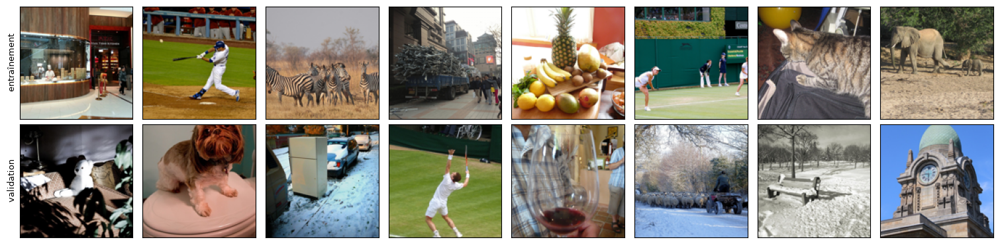

In [ ]:
def afficher(lignes, noms, n=8):
    fig, axes = plt.subplots(len(lignes), n, figsize=(1.9 * n, 1.9 * len(lignes)), squeeze=False)
    for i, images in enumerate(lignes):
        for j in range(n):
            axes[i, j].imshow(np.clip(images[j], 0, 1))
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
        axes[i, 0].set_ylabel(noms[i], fontsize=9)
    plt.tight_layout()
    plt.show()


afficher([X_train_u8[:8] / 255.0, X_val[:8]], ["entraînement", "validation"])

## 3. Création des images bruitées

Nos photos ne contiennent pas de bruit visible. Nous ajoutons donc nous-mêmes le bruit : comme nous connaissons la photo propre, nous pouvons vérifier si le modèle la retrouve.

| Bruit | Principe |
|---|---|
| **Gaussien** | une petite valeur aléatoire est ajoutée à chaque pixel |
| **Sel et poivre** | des pixels pris au hasard deviennent noirs ou blancs |
| **Speckle** | comme le gaussien, mais plus fort sur les zones claires |

Chaque bruit existe en trois intensités : faible, moyenne et forte.

Pour la validation et le test, le bruit est tiré une seule fois : toutes les méthodes sont comparées sur les mêmes images.

In [ ]:
NIVEAUX = {
    "gaussien":   {"faible": 0.05, "moyen": 0.10, "fort": 0.20},
    "sel_poivre": {"faible": 0.02, "moyen": 0.05, "fort": 0.10},
    "speckle":    {"faible": 0.10, "moyen": 0.25, "fort": 0.50},
}
BRUITS = list(NIVEAUX)


def bruit_gaussien(x, intensite):
    return tf.clip_by_value(x + intensite * tf.random.normal(tf.shape(x)), 0.0, 1.0)


def bruit_sel_poivre(x, intensite):
    tirage = tf.random.uniform(tf.shape(x)[:-1])[..., tf.newaxis]
    x = tf.where(tirage < intensite / 2, 0.0, x)
    return tf.where(tirage > 1 - intensite / 2, 1.0, x)


def bruit_speckle(x, intensite):
    return tf.clip_by_value(x + x * intensite * tf.random.normal(tf.shape(x)), 0.0, 1.0)


AJOUTER_BRUIT = {"gaussien": bruit_gaussien, "sel_poivre": bruit_sel_poivre, "speckle": bruit_speckle}


def bruiter_une_fois(X, graine):
    resultat = {}
    for k, (bruit, niveaux) in enumerate(NIVEAUX.items()):
        for n, (niveau, intensite) in enumerate(niveaux.items()):
            tf.random.set_seed(graine + 10 * k + n)
            resultat[(bruit, niveau)] = AJOUTER_BRUIT[bruit](tf.constant(X), intensite).numpy()
    return resultat


VAL_BRUITE = bruiter_une_fois(X_val, 1000)
TEST_BRUITE = bruiter_une_fois(X_test, 2000)

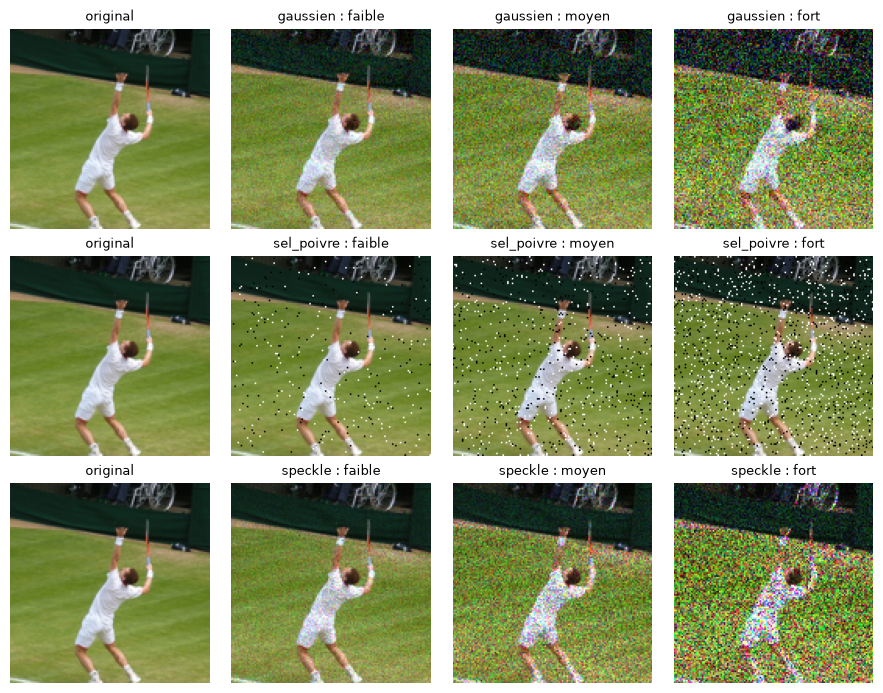

In [ ]:
# Une même photo avec chaque bruit et chaque intensité
i = 3
fig, axes = plt.subplots(3, 4, figsize=(9, 7))
for r, bruit in enumerate(BRUITS):
    axes[r, 0].imshow(X_val[i])
    axes[r, 0].set_title("original", fontsize=9)
    for c, niveau in enumerate(NIVEAUX[bruit], start=1):
        axes[r, c].imshow(VAL_BRUITE[(bruit, niveau)][i])
        axes[r, c].set_title(f"{bruit} : {niveau}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Méthodes de référence : filtres classiques

Avant d'utiliser un réseau de neurones, nous testons trois filtres classiques. Chacun remplace un pixel à partir de ses 8 voisins :

- **filtre moyen** : leur moyenne ;
- **filtre gaussien** : une moyenne où les voisins proches comptent davantage ;
- **filtre médian** : leur valeur du milieu.

Notre auto-encodeur devra faire mieux que ces filtres.

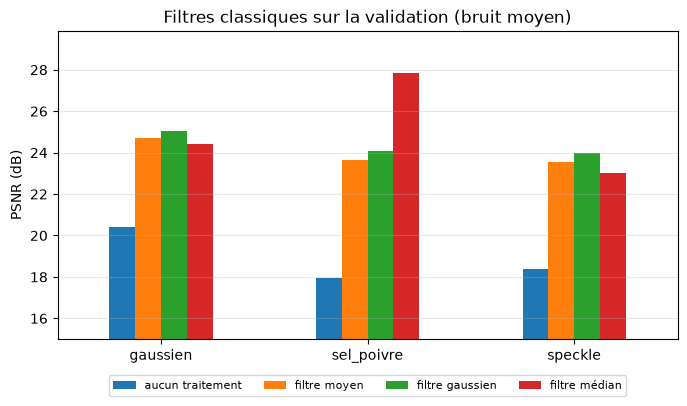

bruit,gaussien,sel_poivre,speckle
méthode,,,
aucun traitement,20.41,17.96,18.38
filtre moyen,24.71,23.63,23.56
filtre gaussien,25.04,24.09,23.97
filtre médian,24.42,27.87,23.02


In [ ]:
def mesurer(images, reference):
    a = tf.constant(np.clip(images, 0, 1), tf.float32)
    b = tf.constant(reference, tf.float32)
    return {
        "psnr": float(tf.reduce_mean(tf.image.psnr(a, b, 1.0))),
        "ssim": float(tf.reduce_mean(tf.image.ssim(a, b, 1.0))),
    }


FILTRES = {
    "aucun traitement": lambda X: X,
    "filtre moyen": lambda X: ndimage.uniform_filter(X, size=(1, 3, 3, 1)),
    "filtre gaussien": lambda X: ndimage.gaussian_filter(X, sigma=(0, 1, 1, 0)),
    "filtre médian": lambda X: ndimage.median_filter(X, size=(1, 3, 3, 1)),
}

lignes = []
for bruit in BRUITS:
    for nom, filtre in FILTRES.items():
        lignes.append({"méthode": nom, "bruit": bruit, **mesurer(filtre(VAL_BRUITE[(bruit, "moyen")]), X_val)})
tableau_filtres = pd.DataFrame(lignes).pivot(index="méthode", columns="bruit", values="psnr").loc[list(FILTRES)]
MEILLEUR_FILTRE = tableau_filtres.drop("aucun traitement").max()

ax = tableau_filtres.T.plot.bar(figsize=(8, 4), rot=0)
ax.set_ylim(15, tableau_filtres.values.max() + 2)
ax.set_ylabel("PSNR (dB)")
ax.set_xlabel("")
ax.set_title("Filtres classiques sur la validation (bruit moyen)")
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.grid(axis="y", alpha=0.3)
plt.show()

display(tableau_filtres.round(2))

### Analyse : filtres classiques

| Bruit moyen | Sans traitement | Meilleur filtre |
|---|---|---|
| Gaussien | 20,4 dB | **25,0 dB** (filtre gaussien) |
| Sel et poivre | 18,0 dB | **27,9 dB** (filtre médian) |
| Speckle | 18,4 dB | **24,0 dB** (filtre gaussien) |

Les filtres améliorent nettement les photos, mais **chacun n'est bon que sur un type de bruit**. Le filtre médian est le meilleur sur le sel et poivre, car il ignore les pixels isolés, mais il est le moins bon sur les deux autres bruits.

Aucun filtre ne convient à tous les bruits : c'est la limite que notre auto-encodeur doit dépasser.

## 5. Construction des auto-encodeurs

Un auto-encodeur a deux parties :

- l'**encodeur** réduit l'image (128 → 64 → 32 pixels de côté) en gardant l'essentiel ;
- le **décodeur** la ramène à sa taille d'origine (32 → 64 → 128).

La dernière couche produit 3 canaux (rouge, vert, bleu), avec des pixels entre 0 et 1.

**Lecture des schémas :** chaque bloc est une couche. Sa hauteur indique la taille de l'image, son épaisseur le nombre de filtres. Le bloc encadré est le « code », la version la plus réduite de l'image.

In [ ]:
COULEURS = {"Entrée": "#9e9e9e", "Conv2D": "#4C78A8", "MaxPooling2D": "#F58518", "UpSampling2D": "#54A24B",
            "Conv2DTranspose": "#B279A2", "Concatenate": "#E45756", "Sortie": "#9e9e9e"}


def schema(titre, couches, liaisons=(), code_latent=None):
    fig, ax = plt.subplots(figsize=(1.15 * len(couches) + 1, 3.6))
    x, centres = 0.0, []

    # Un bloc par couche
    for k, (type_couche, taille, filtres) in enumerate(couches):
        h = 2.2 * taille / 128
        w = 0.18 + 0.09 * np.log2(max(filtres, 2))
        ax.add_patch(Rectangle((x, -h / 2), w, h, fc=COULEURS[type_couche], alpha=0.85,
                               ec="black", lw=2.5 if k == code_latent else 0.5))
        ax.text(x + w / 2, -1.45, f"{type_couche}\n{taille}×{taille}×{filtres}", ha="center", va="top", fontsize=7)
        centres.append((x + w / 2, h / 2))
        x += w + 0.45

    # Flèches des connexions directes
    for k, (a, b) in enumerate(liaisons):
        (xa, ha), (xb, hb) = centres[a], centres[b]
        y = 1.5 + 0.35 * k
        ax.plot([xa, xa, xb], [ha, y, y], color="#E45756", lw=1.6)
        ax.annotate("", xy=(xb, hb), xytext=(xb, y), arrowprops=dict(arrowstyle="-|>", color="#E45756", lw=1.6))
        ax.text((xa + xb) / 2, y + 0.08, "connexion directe", ha="center", fontsize=7, color="#E45756")

    if code_latent is not None:
        xc, hc = centres[code_latent]
        ax.text(xc, -hc - 0.12, "code", ha="center", va="top", fontsize=8, fontweight="bold")

    ax.set_xlim(-0.3, x)
    ax.set_ylim(-2.1, 2.4 if liaisons else 1.4)
    ax.axis("off")
    ax.set_title(titre)
    plt.show()

### Modèle A0 - Modèle de base (issu du workshop)

Notre point de départ est l'auto-encodeur du workshop *Auto-encodeur et traitement d'image*, adapté aux photos en couleur :

- **encodeur** : 2 blocs `Conv2D` (32 filtres) + `MaxPooling2D`, qui divise la taille par deux ;
- **décodeur** : 2 blocs `Conv2D` (32 filtres) + `UpSampling2D`, qui multiplie la taille par deux.

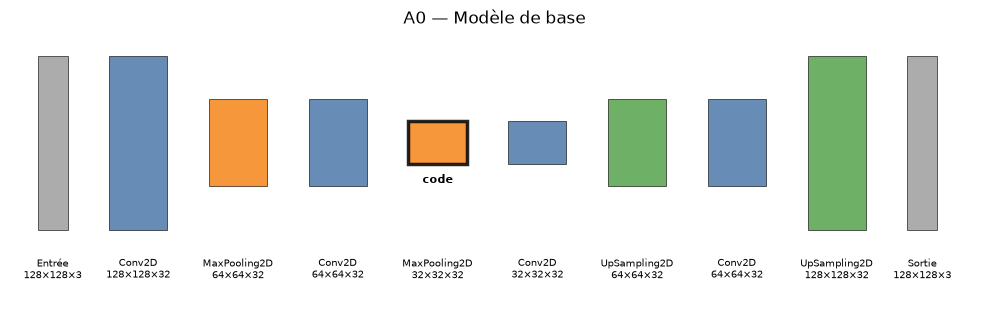

In [ ]:
schema("A0 - Modèle de base",
       [("Entrée", 128, 3), ("Conv2D", 128, 32), ("MaxPooling2D", 64, 32), ("Conv2D", 64, 32),
        ("MaxPooling2D", 32, 32), ("Conv2D", 32, 32), ("UpSampling2D", 64, 32), ("Conv2D", 64, 32),
        ("UpSampling2D", 128, 32), ("Sortie", 128, 3)], code_latent=4)


def modele_A0():
    entree = Input(shape=(None, None, 3))

    # Encodeur
    x = Conv2D(32, (3, 3), activation="relu", padding="same")(entree)
    x = MaxPooling2D((2, 2), padding="same")(x)
    x = Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    code = MaxPooling2D((2, 2), padding="same")(x)

    # Décodeur
    x = Conv2D(32, (3, 3), activation="relu", padding="same")(code)
    x = UpSampling2D((2, 2))(x)
    x = Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    x = UpSampling2D((2, 2))(x)
    sortie = Conv2D(3, (3, 3), activation="sigmoid", padding="same")(x)

    return Model(entree, sortie, name="A0_base")

### Modèle A1 — Plus de filtres

Même structure que A0, avec 64 puis 128 filtres au lieu de 32. Chaque filtre repère un motif (contour, texture, couleur) : plus de filtres, c'est plus de motifs reconnus, mais 10 fois plus de paramètres.

**Question :** un modèle plus large débruite-t-il mieux ?

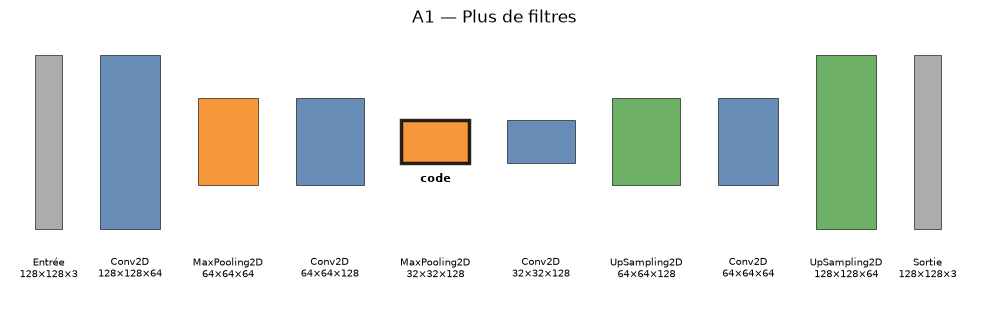

In [ ]:
schema("A1 - Plus de filtres",
       [("Entrée", 128, 3), ("Conv2D", 128, 64), ("MaxPooling2D", 64, 64), ("Conv2D", 64, 128),
        ("MaxPooling2D", 32, 128), ("Conv2D", 32, 128), ("UpSampling2D", 64, 128),
        ("Conv2D", 64, 64), ("UpSampling2D", 128, 64), ("Sortie", 128, 3)], code_latent=4)


def modele_A1():
    entree = Input(shape=(None, None, 3))

    # Encodeur
    x = Conv2D(64, (3, 3), activation="relu", padding="same")(entree)
    x = MaxPooling2D((2, 2), padding="same")(x)
    x = Conv2D(128, (3, 3), activation="relu", padding="same")(x)
    code = MaxPooling2D((2, 2), padding="same")(x)

    # Décodeur
    x = Conv2D(128, (3, 3), activation="relu", padding="same")(code)
    x = UpSampling2D((2, 2))(x)
    x = Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    x = UpSampling2D((2, 2))(x)
    sortie = Conv2D(3, (3, 3), activation="sigmoid", padding="same")(x)

    return Model(entree, sortie, name="A1_plus_de_filtres")

### Modèle A2 — Connexions directes (U-Net)

Dans A0 et A1, toute l'image passe par le code de 32 × 32 pixels : les détails fins sont perdus, et la photo ressort floue.

Nous ajoutons des **connexions directes** (flèches rouges) : chaque étage de l'encodeur est recopié vers l'étage de même taille du décodeur (`Concatenate`). Le décodeur récupère ainsi les détails d'avant la réduction. C'est le principe du réseau **U-Net**, très utilisé en traitement d'image.

**Question :** rendre les détails au décodeur donne-t-il des photos plus nettes ?

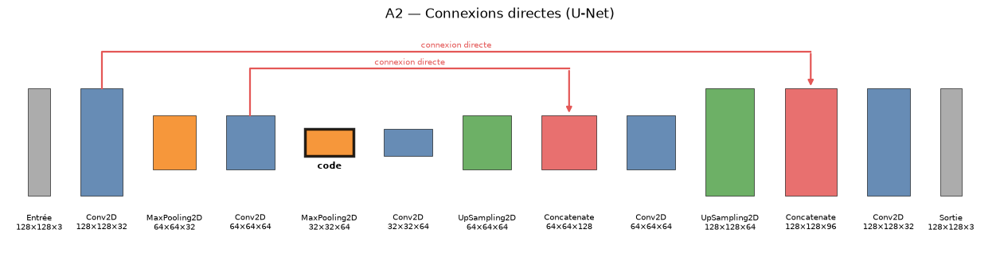

In [ ]:
schema("A2 - Connexions directes (U-Net)",
       [("Entrée", 128, 3), ("Conv2D", 128, 32), ("MaxPooling2D", 64, 32), ("Conv2D", 64, 64), ("MaxPooling2D", 32, 64),
        ("Conv2D", 32, 64), ("UpSampling2D", 64, 64), ("Concatenate", 64, 128), ("Conv2D", 64, 64),
        ("UpSampling2D", 128, 64), ("Concatenate", 128, 96), ("Conv2D", 128, 32), ("Sortie", 128, 3)],
       liaisons=[(3, 7), (1, 10)], code_latent=4)


def modele_A2():
    entree = Input(shape=(None, None, 3))

    # Encodeur (c1 et c2 sont gardés pour les connexions directes)
    c1 = Conv2D(32, (3, 3), activation="relu", padding="same")(entree)
    x = MaxPooling2D((2, 2), padding="same")(c1)
    c2 = Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    code = MaxPooling2D((2, 2), padding="same")(c2)

    # Décodeur
    x = Conv2D(64, (3, 3), activation="relu", padding="same")(code)
    x = UpSampling2D((2, 2))(x)
    x = Concatenate()([x, c2])
    x = Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    x = UpSampling2D((2, 2))(x)
    x = Concatenate()([x, c1])
    x = Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    sortie = Conv2D(3, (3, 3), activation="sigmoid", padding="same")(x)

    return Model(entree, sortie, name="A2_unet")

### Modèle A3 — Réduction apprise

`MaxPooling2D` et `UpSampling2D` réduisent et agrandissent l'image avec une règle fixe. Nous les remplaçons par des couches qui **apprennent** à le faire :

- `Conv2D(strides=2)` : divise la taille par deux ;
- `Conv2DTranspose(strides=2)` : double la taille.

**Question :** laisser le modèle apprendre la réduction améliore-t-il le résultat ?

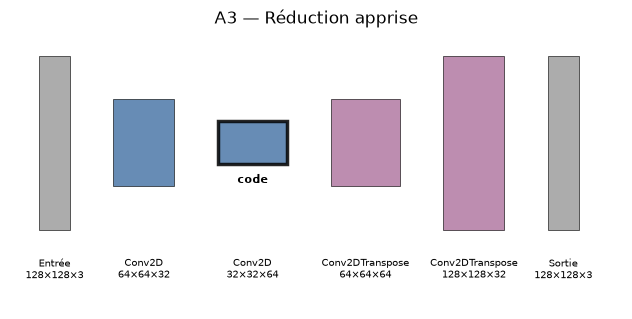

In [ ]:
schema("A3 - Réduction apprise",
       [("Entrée", 128, 3), ("Conv2D", 64, 32), ("Conv2D", 32, 64), ("Conv2DTranspose", 64, 64),
        ("Conv2DTranspose", 128, 32), ("Sortie", 128, 3)], code_latent=2)


def modele_A3():
    entree = Input(shape=(None, None, 3))

    # Encodeur : chaque convolution divise la taille par deux
    x = Conv2D(32, (3, 3), strides=2, activation="relu", padding="same")(entree)
    code = Conv2D(64, (3, 3), strides=2, activation="relu", padding="same")(x)
    
    # Décodeur : chaque convolution transposée double la taille
    x = Conv2DTranspose(64, (3, 3), strides=2, activation="relu", padding="same")(code)
    x = Conv2DTranspose(32, (3, 3), strides=2, activation="relu", padding="same")(x)
    sortie = Conv2D(3, (3, 3), activation="sigmoid", padding="same")(x)

    return Model(entree, sortie, name="A3_reduction_apprise")

In [ ]:
ARCHITECTURES = {
    "A0 Modèle de base": modele_A0,
    "A1 Plus de filtres": modele_A1,
    "A2 Connexions directes": modele_A2,
    "A3 Réduction apprise": modele_A3,
}

display(pd.DataFrame({
    "modèle": list(ARCHITECTURES),
    "paramètres": [construire().count_params() for construire in ARCHITECTURES.values()],
}))

,modèle,paramètres
0,A0 Modèle de base,29507
1,A1 Plus de filtres,298755
2,A2 Connexions directes,158659
3,A3 Réduction apprise,75651


## 6. Préparation des données d'entraînement

Le modèle reçoit la **photo bruitée en entrée** et doit produire la **photo propre en sortie**. Les paires sont préparées par lots de 32, pendant l'entraînement :

1. les photos sont mélangées ;
2. les pixels sont ramenés entre 0 et 1 ;
3. une photo sur deux est retournée horizontalement, pour varier les exemples ;
4. un bruit est ajouté, avec une intensité tirée au hasard entre « faible » et « fort » ;
5. on forme la paire (photo bruitée, photo propre).

Le bruit change à chaque passage : le modèle ne voit jamais deux fois la même photo bruitée, ce qui l'empêche d'apprendre les photos par cœur.

Entrée : (32, 128, 128, 3) - Cible : (32, 128, 128, 3)


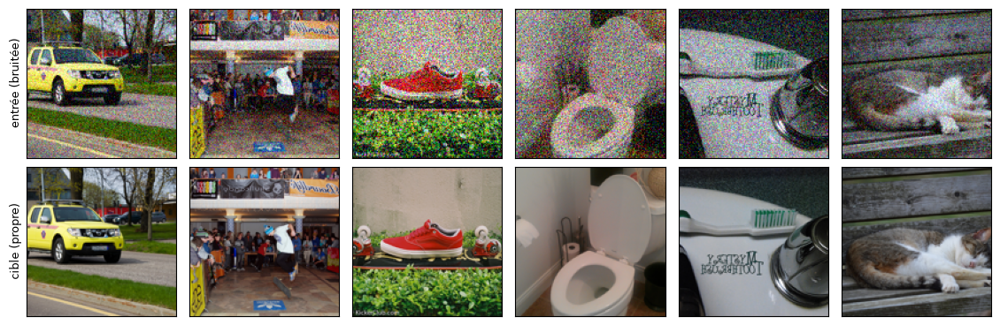

In [ ]:
def donnees_entrainement(bruit):

    def bruiter_avec(x, type_bruit):
        niveaux = NIVEAUX[type_bruit]
        intensite = tf.random.uniform([], niveaux["faible"], niveaux["fort"])
        return AJOUTER_BRUIT[type_bruit](x, intensite)

    def bruiter(x):
        if bruit == "mixte":
            choix = tf.random.uniform([], 0, len(BRUITS), dtype=tf.int32)
            return tf.switch_case(choix, [lambda b=b: bruiter_avec(x, b) for b in BRUITS])
        return bruiter_avec(x, bruit)

    ds = tf.data.Dataset.from_tensor_slices(X_train_u8)
    ds = ds.shuffle(5000, seed=SEED)
    ds = ds.map(lambda img: tf.cast(img, tf.float32) / 255.0)
    ds = ds.map(tf.image.random_flip_left_right)
    ds = ds.map(lambda propre: (bruiter(propre), propre), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(2)


# Vérification sur un lot
x_lot, y_lot = next(iter(donnees_entrainement("gaussien")))
print("Entrée :", x_lot.shape, "- Cible :", y_lot.shape)
afficher([x_lot.numpy(), y_lot.numpy()], ["entrée (bruitée)", "cible (propre)"], n=6)

## 7. Entraînement du modèle de base

Nous entraînons A0 en trois étapes :

1. **construire** le modèle ;
2. **compiler** : optimiseur Adam avec un taux d'apprentissage de 0,001, fonction de perte BCE (entropie croisée binaire) ;
3. **entraîner** avec `fit` : au plus 25 passages sur les données (époques). L'entraînement s'arrête plus tôt si l'erreur de validation ne baisse plus pendant 4 époques (early stopping).

Chaque ligne affichée correspond à une époque : `loss` est l'erreur sur l'entraînement, `val_loss` l'erreur sur la validation.

In [ ]:
keras.utils.set_random_seed(SEED)

autoencoder = modele_A0()
autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="binary_crossentropy")

arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
history = autoencoder.fit(
    donnees_entrainement("gaussien"),
    epochs=EPOCHS,
    validation_data=(VAL_BRUITE[("gaussien", "moyen")], X_val),
    callbacks=[arret],
    shuffle=False,
    verbose=2,
)

Epoch 1/25
125/125 - 6s - 49ms/step - loss: 0.5701 - val_loss: 0.5494
Epoch 2/25
125/125 - 2s - 19ms/step - loss: 0.5369 - val_loss: 0.5415
Epoch 3/25
125/125 - 2s - 19ms/step - loss: 0.5330 - val_loss: 0.5391
Epoch 4/25
125/125 - 2s - 19ms/step - loss: 0.5316 - val_loss: 0.5379
Epoch 5/25
125/125 - 2s - 19ms/step - loss: 0.5306 - val_loss: 0.5379
Epoch 6/25
125/125 - 2s - 19ms/step - loss: 0.5300 - val_loss: 0.5370
Epoch 7/25
125/125 - 2s - 19ms/step - loss: 0.5292 - val_loss: 0.5363
Epoch 8/25
125/125 - 2s - 19ms/step - loss: 0.5287 - val_loss: 0.5356
Epoch 9/25
125/125 - 2s - 19ms/step - loss: 0.5290 - val_loss: 0.5379
Epoch 10/25
125/125 - 2s - 19ms/step - loss: 0.5283 - val_loss: 0.5351
Epoch 11/25
125/125 - 2s - 19ms/step - loss: 0.5278 - val_loss: 0.5347
Epoch 12/25
125/125 - 2s - 19ms/step - loss: 0.5277 - val_loss: 0.5355
Epoch 13/25
125/125 - 2s - 19ms/step - loss: 0.5274 - val_loss: 0.5352
Epoch 14/25
125/125 - 2s - 19ms/step - loss: 0.5273 - val_loss: 0.5342
Epoch 15/25
125

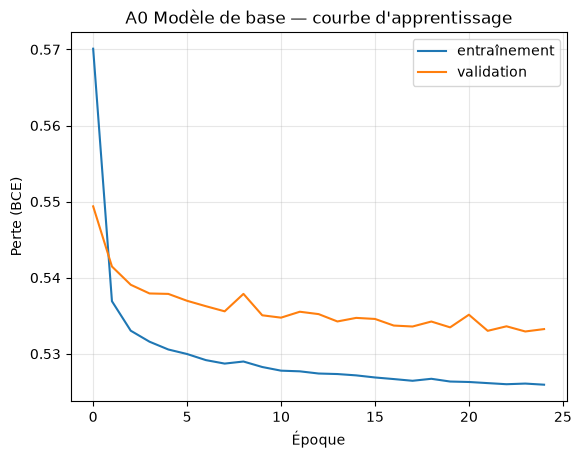

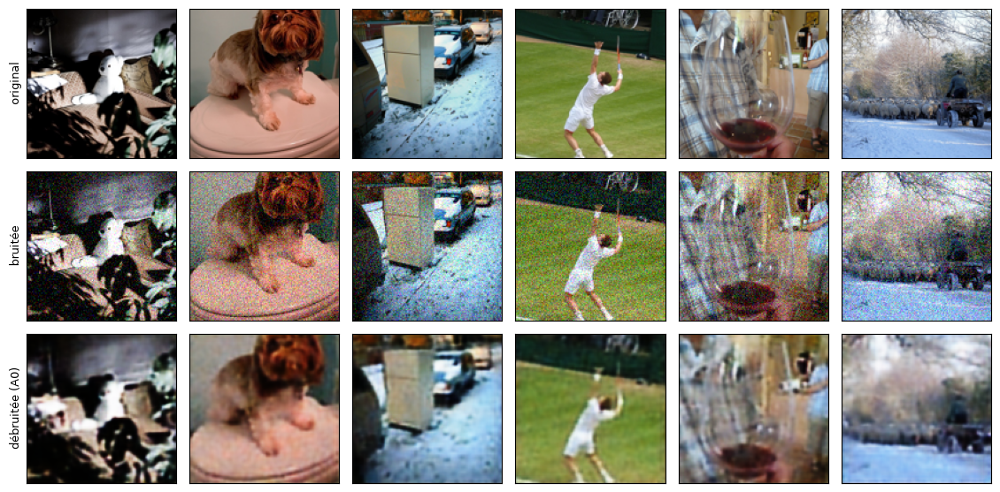

In [ ]:
plt.plot(history.history["loss"], label="entraînement")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("Époque")
plt.ylabel("Perte (BCE)")
plt.title("A0 Modèle de base - courbe d'apprentissage")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

x_bruite = VAL_BRUITE[("gaussien", "moyen")]
images_debruitees = autoencoder.predict(x_bruite, verbose=0)
afficher([X_val, x_bruite, images_debruitees], ["original", "bruitée", "débruitée (A0)"], n=6)

### Analyse des courbes : modèle de base

Les deux courbes baissent vite puis se stabilisent, et restent proches : le modèle apprend sans apprendre par cœur, **il n'y a pas de surapprentissage**.

Le bruit disparaît, mais **les photos sont floues** : avec 32 filtres et une image réduite à 32 × 32 pixels, le modèle perd les détails. C'est ce que nous cherchons à améliorer.

## 8. Comparaison des architectures

### Pourquoi entraîner d'autres modèles ?

Un modèle entraîné ne peut plus être modifié : son architecture, sa perte, son taux d'apprentissage et le bruit appris sont fixés. **Pour tester un autre réglage, il faut entraîner un nouveau modèle.**

Au total, nous entraînons 11 modèles, chacun avec une seule différence :

| Section | Modèles entraînés | Ce qui change |
|---|---|---|
| 7 | A0 | modèle de base |
| 8 | A1, A2, A3 | l'architecture |
| 9 | MSE, MAE | la fonction de perte |
| 9 | taux 0,003 et 0,0003 | le taux d'apprentissage |
| 10 | sel et poivre, speckle, mixte | le bruit appris |

La fonction `entrainer` reprend exactement les trois étapes de la section 7, avec la même graine aléatoire : seul le réglage testé change.

In [ ]:
modeles = {"A0 Modèle de base": autoencoder}
historiques = {"A0 Modèle de base": history.history}


def entrainer(nom, construire, bruit="gaussien", perte="binary_crossentropy", taux=0.001):
    print(f"--- Entraînement : {nom} ---")
    keras.utils.set_random_seed(SEED)

    modele = construire()
    modele.compile(optimizer=keras.optimizers.Adam(learning_rate=taux), loss=perte)

    # Validation sur le bruit appris (les trois bruits pour le modèle mixte)
    bruits_val = BRUITS if bruit == "mixte" else [bruit]
    x_val = np.concatenate([VAL_BRUITE[(b, "moyen")] for b in bruits_val])
    y_val = np.concatenate([X_val] * len(bruits_val))

    debut = time.perf_counter()
    historique = modele.fit(
        donnees_entrainement(bruit),
        epochs=EPOCHS,
        validation_data=(x_val, y_val),
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)],
        shuffle=False,
        verbose=2,
    )
    print(f"=> {len(historique.history['loss'])} époques en {time.perf_counter() - debut:.0f} s\n")

    modeles[nom] = modele
    historiques[nom] = historique.history
    return modele


def score(modele, bruit, niveau="moyen"):
    prediction = modele.predict(VAL_BRUITE[(bruit, niveau)], batch_size=16, verbose=0)
    return mesurer(prediction, X_val)

In [ ]:
for nom, construire in ARCHITECTURES.items():
    if nom not in modeles:
        entrainer(nom, construire)

resultats_archi = pd.DataFrame([
    {"modèle": nom, "paramètres": modeles[nom].count_params(), **score(modeles[nom], "gaussien")}
    for nom in ARCHITECTURES
]).set_index("modèle")

display(resultats_archi.round(3))

--- Entraînement : A1 Plus de filtres ---
Epoch 1/25
125/125 - 8s - 60ms/step - loss: 0.5694 - val_loss: 0.5454
Epoch 2/25
125/125 - 5s - 43ms/step - loss: 0.5343 - val_loss: 0.5389
Epoch 3/25
125/125 - 5s - 43ms/step - loss: 0.5309 - val_loss: 0.5374
Epoch 4/25
125/125 - 5s - 43ms/step - loss: 0.5289 - val_loss: 0.5354
Epoch 5/25
125/125 - 5s - 43ms/step - loss: 0.5287 - val_loss: 0.5349
Epoch 6/25
125/125 - 5s - 43ms/step - loss: 0.5275 - val_loss: 0.5341
Epoch 7/25
125/125 - 5s - 43ms/step - loss: 0.5271 - val_loss: 0.5344
Epoch 8/25
125/125 - 5s - 43ms/step - loss: 0.5266 - val_loss: 0.5335
Epoch 9/25
125/125 - 5s - 43ms/step - loss: 0.5266 - val_loss: 0.5334
Epoch 10/25
125/125 - 5s - 43ms/step - loss: 0.5261 - val_loss: 0.5329
Epoch 11/25
125/125 - 5s - 43ms/step - loss: 0.5253 - val_loss: 0.5324
Epoch 12/25
125/125 - 5s - 43ms/step - loss: 0.5252 - val_loss: 0.5322
Epoch 13/25
125/125 - 5s - 43ms/step - loss: 0.5253 - val_loss: 0.5318
Epoch 14/25
125/125 - 5s - 43ms/step - loss:

,paramètres,psnr,ssim
modèle,,,
A0 Modèle de base,29507,24.677,0.746
A1 Plus de filtres,298755,26.180,0.804
A2 Connexions directes,158659,28.579,0.853
A3 Réduction apprise,75651,26.667,0.792


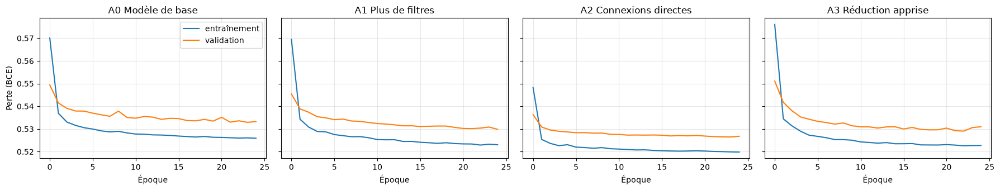

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5), sharey=True)
for ax, nom in zip(axes, ARCHITECTURES):
    ax.plot(historiques[nom]["loss"], label="entraînement")
    ax.plot(historiques[nom]["val_loss"], label="validation")
    ax.set_title(nom)
    ax.set_xlabel("Époque")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Perte (BCE)")
axes[0].legend()
plt.tight_layout()
plt.show()

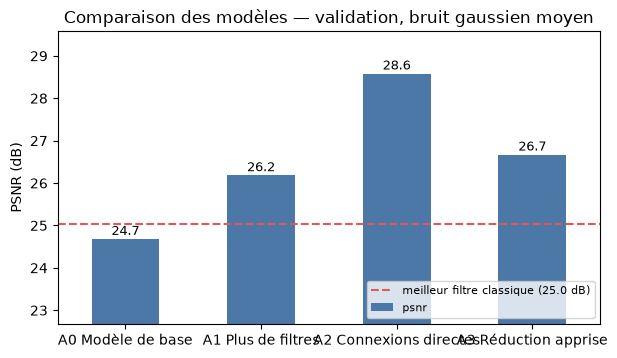

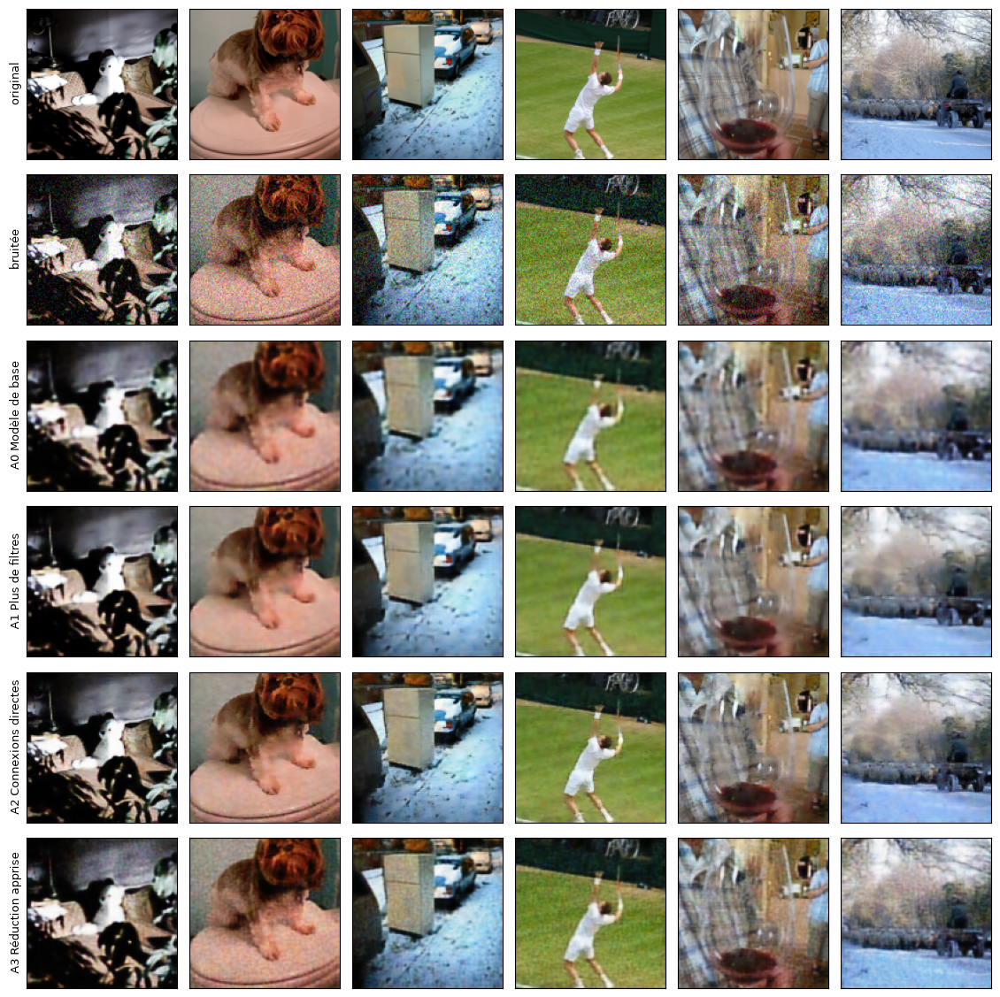

Modèle retenu : A2 Connexions directes


In [ ]:
def barres(valeurs, titre, reference=None):
    ax = valeurs.plot.bar(figsize=(7, 3.8), rot=0, color="#4C78A8")
    for k, v in enumerate(valeurs):
        ax.text(k, v + 0.1, f"{v:.1f}", ha="center", fontsize=9)
    if reference is not None:
        ax.axhline(reference, ls="--", color="#E45756", label=f"meilleur filtre classique ({reference:.1f} dB)")
        ax.legend(fontsize=8, loc="lower right")
    ax.set_ylim(min(valeurs.min(), reference or 99) - 2, valeurs.max() + 1)
    ax.set_ylabel("PSNR (dB)")
    ax.set_xlabel("")
    ax.set_title(titre)
    plt.show()


barres(resultats_archi["psnr"], "Comparaison des modèles - validation, bruit gaussien moyen",
       MEILLEUR_FILTRE["gaussien"])

afficher([X_val, x_bruite] + [modeles[nom].predict(x_bruite[:8], verbose=0) for nom in ARCHITECTURES],
         ["original", "bruitée"] + list(ARCHITECTURES), n=6)

ARCHI = resultats_archi["psnr"].idxmax()
print("Modèle retenu :", ARCHI)

### Analyse : comparaison des architectures

| Modèle | PSNR | SSIM | Paramètres |
|---|---|---|---|
| A0 Modèle de base | 24,7 dB | 0,746 | 29 507 |
| A1 Plus de filtres | 26,2 dB | 0,804 | 298 755 |
| A3 Réduction apprise | 26,7 dB | 0,792 | 75 651 |
| **A2 Connexions directes** | **28,6 dB** | **0,853** | 158 659 |
| *Meilleur filtre classique* | *25,0 dB* | | |

- **Le modèle de base fait moins bien qu'un simple filtre** (24,7 contre 25,0 dB) : il rend les photos floues.
- **A1 et A3** gagnent 1,5 à 2 dB. A1 coûte 10 fois plus de paramètres.
- **A2 est nettement le meilleur** : +3,9 dB par rapport au modèle de base, avec moitié moins de paramètres que A1. C'est le seul qui garde des contours nets.
- Les courbes de validation restent proches de celles d'entraînement : pas de surapprentissage.

**Nous retenons A2.**

## 9. Réglage de la fonction de perte et du taux d'apprentissage

Nous gardons A2 et changeons un seul réglage à la fois.

**La fonction de perte** calcule l'erreur que le modèle cherche à réduire :

| Perte | Calcul | Effet |
|---|---|---|
| **BCE** (modèle de base) | entropie croisée | adaptée aux valeurs entre 0 et 1 |
| **MSE** | carré de l'écart | punit fortement les grosses erreurs |
| **MAE** | valeur absolue de l'écart | punit moins les grosses erreurs |

**Le taux d'apprentissage** est la taille des corrections à chaque étape. Nous testons 0,003 (grands pas), 0,001 (valeur de départ) et 0,0003 (petits pas).

In [ ]:
# Fonction de perte (le modèle BCE est celui de la section 8)
modeles["BCE"] = modeles[ARCHI]
historiques["BCE"] = historiques[ARCHI]
for nom, perte in [("MSE", "mse"), ("MAE", "mae")]:
    entrainer(nom, ARCHITECTURES[ARCHI], perte=perte)

psnr_pertes = pd.Series({nom: score(modeles[nom], "gaussien")["psnr"] for nom in ["BCE", "MSE", "MAE"]})
NOM_PERTE = psnr_pertes.idxmax()
PERTE = {"BCE": "binary_crossentropy", "MSE": "mse", "MAE": "mae"}[NOM_PERTE]

# Taux d'apprentissage (le taux 0,001 est celui du modèle précédent)
modeles["0.001"] = modeles[NOM_PERTE]
historiques["0.001"] = historiques[NOM_PERTE]
for taux in [0.003, 0.0003]:
    entrainer(str(taux), ARCHITECTURES[ARCHI], perte=PERTE, taux=taux)

psnr_taux = pd.Series({nom: score(modeles[nom], "gaussien")["psnr"] for nom in ["0.003", "0.001", "0.0003"]})
NOM_TAUX = psnr_taux.idxmax()
TAUX = float(NOM_TAUX)

print("Perte retenue :", NOM_PERTE, "- Taux d'apprentissage retenu :", TAUX)

--- Entraînement : MSE ---
Epoch 1/25
125/125 - 8s - 61ms/step - loss: 0.0129 - val_loss: 0.0037
Epoch 2/25
125/125 - 5s - 44ms/step - loss: 0.0037 - val_loss: 0.0027
Epoch 3/25
125/125 - 5s - 44ms/step - loss: 0.0034 - val_loss: 0.0023
Epoch 4/25
125/125 - 5s - 44ms/step - loss: 0.0029 - val_loss: 0.0023
Epoch 5/25
125/125 - 5s - 44ms/step - loss: 0.0028 - val_loss: 0.0022
Epoch 6/25
125/125 - 5s - 44ms/step - loss: 0.0027 - val_loss: 0.0023
Epoch 7/25
125/125 - 5s - 44ms/step - loss: 0.0026 - val_loss: 0.0019
Epoch 8/25
125/125 - 6s - 45ms/step - loss: 0.0025 - val_loss: 0.0019
Epoch 9/25
125/125 - 6s - 44ms/step - loss: 0.0025 - val_loss: 0.0018
Epoch 10/25
125/125 - 6s - 44ms/step - loss: 0.0024 - val_loss: 0.0018
Epoch 11/25
125/125 - 6s - 45ms/step - loss: 0.0024 - val_loss: 0.0018
Epoch 12/25
125/125 - 6s - 45ms/step - loss: 0.0023 - val_loss: 0.0018
Epoch 13/25
125/125 - 6s - 45ms/step - loss: 0.0023 - val_loss: 0.0017
Epoch 14/25
125/125 - 6s - 44ms/step - loss: 0.0023 - val_l

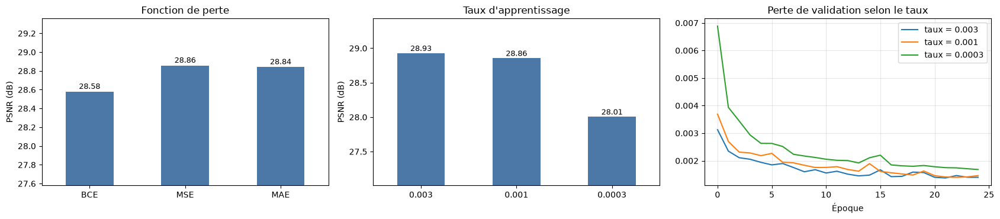

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for ax, serie, titre in [(axes[0], psnr_pertes, "Fonction de perte"), (axes[1], psnr_taux, "Taux d'apprentissage")]:
    serie.plot.bar(ax=ax, rot=0, color="#4C78A8")
    for k, v in enumerate(serie):
        ax.text(k, v + 0.03, f"{v:.2f}", ha="center", fontsize=9)
    ax.set_ylim(serie.min() - 1, serie.max() + 0.5)
    ax.set_ylabel("PSNR (dB)")
    ax.set_title(titre)

for nom in ["0.003", "0.001", "0.0003"]:
    axes[2].plot(historiques[nom]["val_loss"], label=f"taux = {nom}")
axes[2].set_title("Perte de validation selon le taux")
axes[2].set_xlabel("Époque")
axes[2].legend()
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Analyse : perte et taux d'apprentissage

| Réglage | PSNR |
|---|---|
| Perte BCE | 28,58 dB |
| **Perte MSE** | **28,86 dB** |
| Perte MAE | 28,84 dB |
| **Taux 0,003** | **28,93 dB** |
| Taux 0,001 | 28,86 dB |
| Taux 0,0003 | 28,01 dB |

- **Perte** : la MSE et la MAE font mieux que la BCE. Nous retenons la **MSE**.
- **Taux d'apprentissage** : 0,003 et 0,001 donnent presque le même résultat. Avec 0,0003, l'apprentissage est trop lent : la courbe descend moins vite et reste au-dessus des autres. Nous retenons **0,003**.
- **Ces écarts sont faibles** (moins de 1 dB) comparés à celui de l'architecture (+3,9 dB) : **le choix du modèle compte bien plus que ces réglages.**

## 10. Un modèle pour tous les bruits

Jusqu'ici, nos modèles n'ont appris que le bruit gaussien. Or chez TouNum, on ne sait pas à l'avance quel bruit touche une photo.

Avec A2 et les réglages retenus, nous entraînons :

- un modèle pour le **sel et poivre** et un pour le **speckle** (celui du gaussien existe déjà) ;
- un **modèle mixte**, qui apprend les trois bruits à la fois.

Chaque modèle est testé sur les trois bruits, y compris ceux qu'il n'a jamais appris.

--- Entraînement : sel_poivre ---
Epoch 1/25
125/125 - 8s - 62ms/step - loss: 0.0149 - val_loss: 0.0042
Epoch 2/25
125/125 - 6s - 45ms/step - loss: 0.0039 - val_loss: 0.0031
Epoch 3/25
125/125 - 6s - 45ms/step - loss: 0.0028 - val_loss: 0.0028
Epoch 4/25
125/125 - 6s - 45ms/step - loss: 0.0022 - val_loss: 0.0016
Epoch 5/25
125/125 - 6s - 45ms/step - loss: 0.0016 - val_loss: 0.0012
Epoch 6/25
125/125 - 6s - 45ms/step - loss: 0.0013 - val_loss: 0.0010
Epoch 7/25
125/125 - 6s - 45ms/step - loss: 0.0011 - val_loss: 9.1385e-04
Epoch 8/25
125/125 - 6s - 45ms/step - loss: 9.8956e-04 - val_loss: 8.1097e-04
Epoch 9/25
125/125 - 6s - 45ms/step - loss: 0.0011 - val_loss: 7.2976e-04
Epoch 10/25
125/125 - 6s - 46ms/step - loss: 8.1199e-04 - val_loss: 6.7163e-04
Epoch 11/25
125/125 - 6s - 45ms/step - loss: 7.7407e-04 - val_loss: 6.8041e-04
Epoch 12/25
125/125 - 6s - 45ms/step - loss: 7.9349e-04 - val_loss: 6.0191e-04
Epoch 13/25
125/125 - 6s - 45ms/step - loss: 6.8957e-04 - val_loss: 5.7635e-04
Epoc

W0000 00:00:1791971082.623452   12432 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1791970932301213290 in buffer 'PrefetchDataset/_15' sat unconsumed for 150.322 seconds!


125/125 - 156s - 1s/step - loss: 0.0021 - val_loss: 0.0016
Epoch 15/25
125/125 - 6s - 45ms/step - loss: 0.0021 - val_loss: 0.0016
Epoch 16/25
125/125 - 6s - 44ms/step - loss: 0.0020 - val_loss: 0.0017
Epoch 17/25
125/125 - 5s - 43ms/step - loss: 0.0019 - val_loss: 0.0017
Epoch 18/25
125/125 - 5s - 44ms/step - loss: 0.0020 - val_loss: 0.0015
Epoch 19/25
125/125 - 5s - 44ms/step - loss: 0.0019 - val_loss: 0.0015
Epoch 20/25
125/125 - 5s - 44ms/step - loss: 0.0019 - val_loss: 0.0015
Epoch 21/25
125/125 - 5s - 44ms/step - loss: 0.0019 - val_loss: 0.0014
Epoch 22/25
125/125 - 5s - 44ms/step - loss: 0.0018 - val_loss: 0.0013
Epoch 23/25
125/125 - 5s - 44ms/step - loss: 0.0018 - val_loss: 0.0013
Epoch 24/25
125/125 - 5s - 44ms/step - loss: 0.0018 - val_loss: 0.0014
Epoch 25/25
125/125 - 5s - 44ms/step - loss: 0.0018 - val_loss: 0.0015
=> 25 époques en 149 s



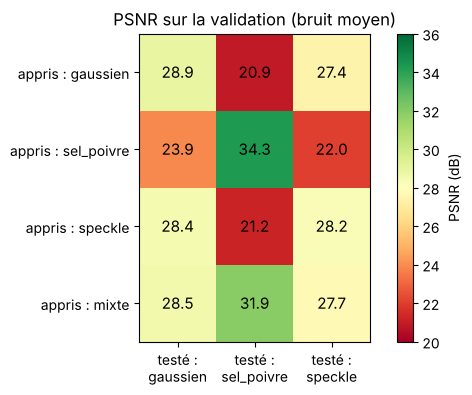

In [ ]:
modeles["gaussien"] = modeles[NOM_TAUX]
for bruit in ["sel_poivre", "speckle", "mixte"]:
    entrainer(bruit, ARCHITECTURES[ARCHI], bruit=bruit, perte=PERTE, taux=TAUX)

croise = pd.DataFrame({
    bruit_teste: {f"appris : {b}": score(modeles[b], bruit_teste)["psnr"] for b in BRUITS + ["mixte"]}
    for bruit_teste in BRUITS
})

fig, ax = plt.subplots(figsize=(7, 4))
image = ax.imshow(croise.values, cmap="RdYlGn", vmin=20, vmax=36)
for r in range(croise.shape[0]):
    for c in range(croise.shape[1]):
        ax.text(c, r, f"{croise.iloc[r, c]:.1f}", ha="center", va="center", fontsize=11)
ax.set_xticks(range(3))
ax.set_xticklabels([f"testé :\n{b}" for b in BRUITS])
ax.set_yticks(range(4))
ax.set_yticklabels(croise.index)
plt.colorbar(image, label="PSNR (dB)")
plt.title("PSNR sur la validation (bruit moyen)")
plt.show()

### Analyse : un modèle pour tous les bruits

Chaque ligne est un modèle, chaque colonne un bruit testé.

- **Un modèle spécialisé échoue sur un bruit qu'il ne connaît pas** : le modèle gaussien tombe à 20,9 dB sur le sel et poivre, bien en dessous du simple filtre médian (27,9 dB).
- **Le modèle mixte est bon partout** : à 0,5 dB des spécialistes sur le gaussien et le speckle, et 31,9 dB sur le sel et poivre, au-dessus du filtre médian.

**Nous retenons le modèle mixte**, le seul utilisable quand le bruit est inconnu.

## 11. Évaluation finale sur le test

Le modèle final est figé : **A2, perte MSE, taux d'apprentissage 0,003, entraîné sur les trois bruits**. Il a été choisi uniquement à partir de la validation.

Nous le mesurons **une seule fois** sur les 74 photos de test, face aux filtres classiques, pour les trois bruits et les trois intensités.

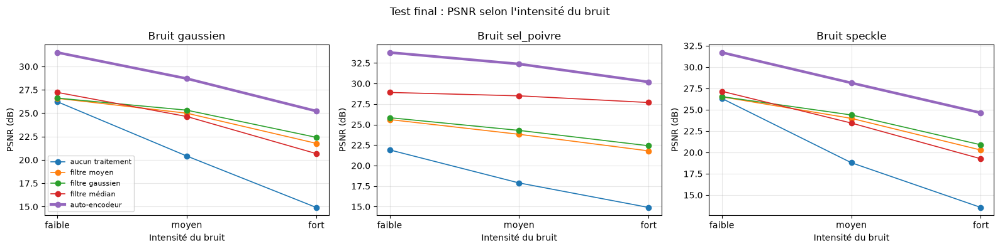

psnr                        ssim                   
bruit            gaussien sel_poivre speckle gaussien sel_poivre speckle
méthode                                                                 
aucun traitement   20.415     17.888  18.793    0.447      0.472   0.489
filtre moyen       24.999     23.813  23.993    0.681      0.639   0.668
filtre gaussien    25.324     24.289  24.392    0.721      0.680   0.706
filtre médian      24.645     28.501  23.444    0.637      0.885   0.629
auto-encodeur      28.705     32.382  28.150    0.854      0.939   0.851

In [ ]:
modele_final = modeles["mixte"]

lignes = []
for bruit in BRUITS:
    for niveau in NIVEAUX[bruit]:
        x = TEST_BRUITE[(bruit, niveau)]
        for nom, filtre in FILTRES.items():
            lignes.append({"bruit": bruit, "niveau": niveau, "méthode": nom, **mesurer(filtre(x), X_test)})
        prediction = modele_final.predict(x, batch_size=16, verbose=0)
        lignes.append({"bruit": bruit, "niveau": niveau, "méthode": "auto-encodeur", **mesurer(prediction, X_test)})
final = pd.DataFrame(lignes)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, bruit in zip(axes, BRUITS):
    for methode in list(FILTRES) + ["auto-encodeur"]:
        d = final[(final["bruit"] == bruit) & (final["méthode"] == methode)]
        ax.plot(list(NIVEAUX[bruit]), d["psnr"], marker="o", label=methode,
                lw=3 if methode == "auto-encodeur" else 1.2)
    ax.set_title(f"Bruit {bruit}")
    ax.set_xlabel("Intensité du bruit")
    ax.set_ylabel("PSNR (dB)")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.suptitle("Test final : PSNR selon l'intensité du bruit")
plt.tight_layout()
plt.show()

moyen = final[final["niveau"] == "moyen"].pivot(index="méthode", columns="bruit", values=["psnr", "ssim"])
display(moyen.loc[list(FILTRES) + ["auto-encodeur"]].round(3))

### Analyse : test final

| Bruit moyen | Meilleur filtre | Notre modèle | Gain |
|---|---|---|---|
| Gaussien | 25,3 dB (filtre gaussien) | **28,7 dB** | **+3,4 dB** |
| Sel et poivre | 28,5 dB (filtre médian) | **32,4 dB** | **+3,9 dB** |
| Speckle | 24,4 dB (filtre gaussien) | **28,2 dB** | **+3,8 dB** |

- **Notre modèle est le meilleur dans les 9 cas** (3 bruits × 3 intensités), y compris au bruit fort.
- Le gain est d'environ 4 dB : **l'erreur est divisée par plus de deux** par rapport au meilleur filtre.
- Le SSIM le confirme : 0,85 contre 0,72 sur le bruit gaussien, 0,85 contre 0,71 sur le speckle. Les contours sont mieux conservés.
- Les résultats du test sont proches de ceux de la validation : le modèle fonctionne aussi bien sur des photos jamais vues.

## 12. Étude de cas

### 12.1 Avant / après pour chaque bruit

Pour chaque bruit d'intensité moyenne : la photo d'origine, la photo bruitée, le filtre médian et notre modèle.

Bruit gaussien, intensité moyenne


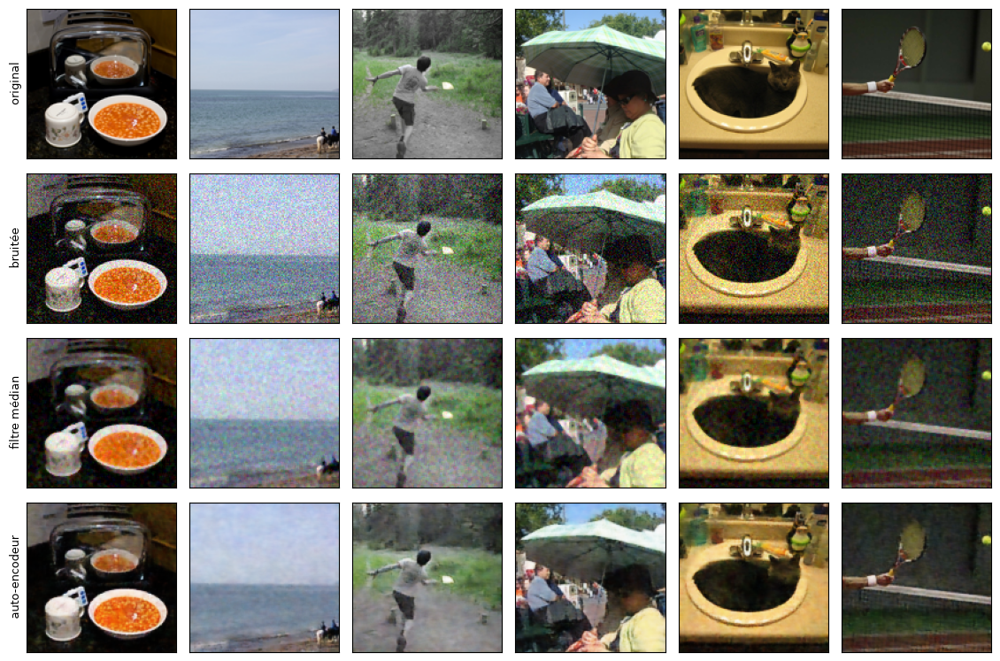

Bruit sel_poivre, intensité moyenne


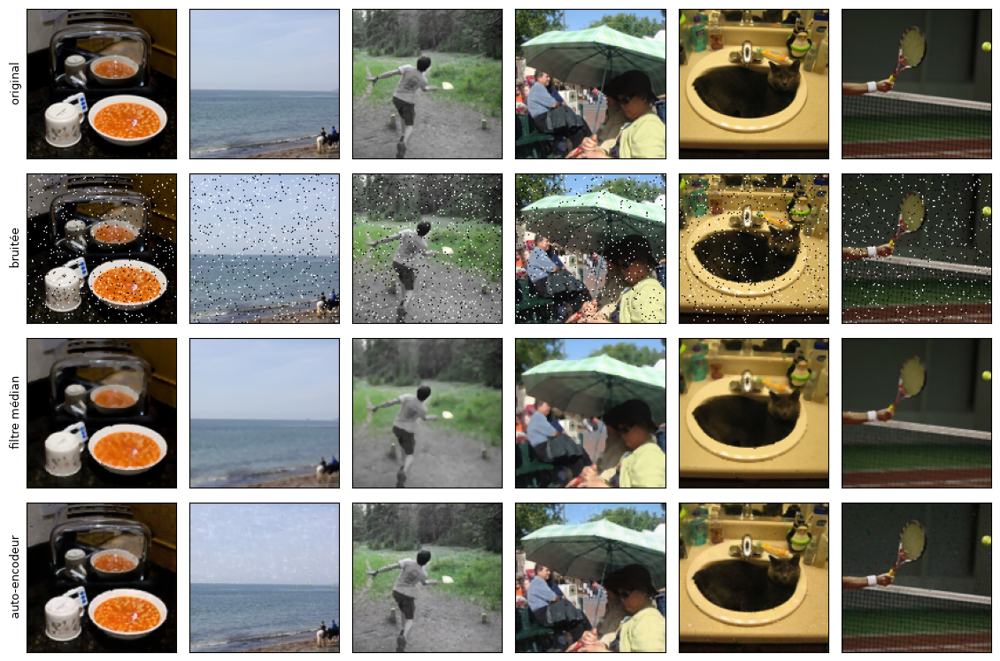

Bruit speckle, intensité moyenne


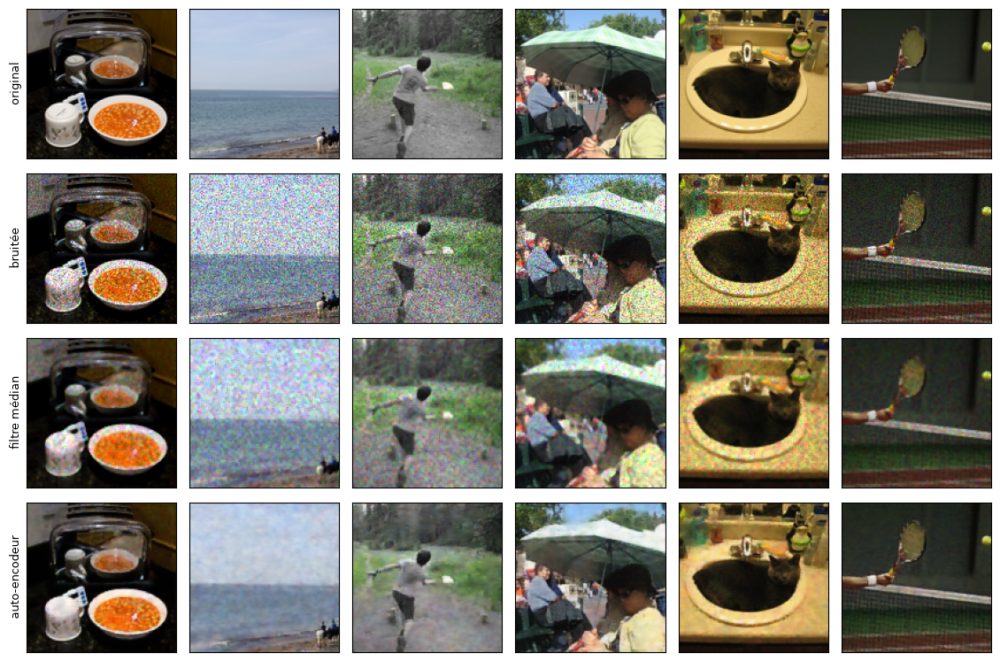

In [ ]:
for bruit in BRUITS:
    x = TEST_BRUITE[(bruit, "moyen")]
    print(f"Bruit {bruit}, intensité moyenne")
    afficher([X_test, x, FILTRES["filtre médian"](x[:6]), modele_final.predict(x[:6], verbose=0)],
             ["original", "bruitée", "filtre médian", "auto-encodeur"], n=6)

### 12.2 Sur quelles photos le modèle est-il le plus efficace ?

Pour chaque photo de test (bruit gaussien moyen), nous mesurons **le gain apporté par le modèle** en PSNR et en SSIM, et nous le comparons à la quantité de détails de la photo.

**Attention :** un fort gain ne veut pas dire que la photo débruitée est la plus belle. Il mesure seulement **à quel point le modèle a amélioré la photo bruitée**.

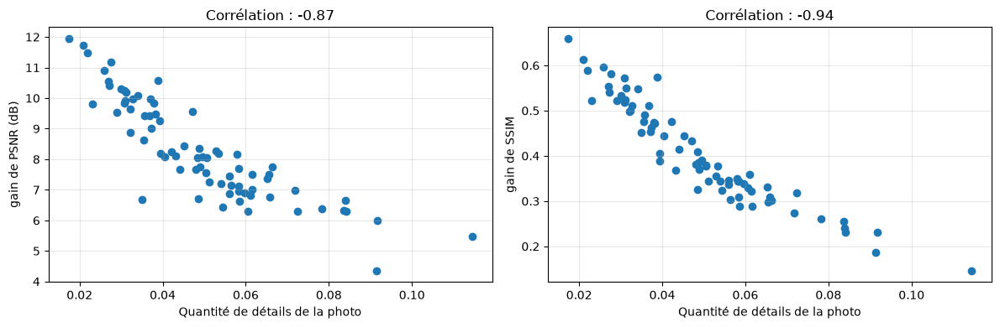

Les 3 plus forts gains de PSNR


,gain PSNR (dB),gain SSIM,détails
0,11.942,0.659,0.017
1,11.729,0.613,0.021
2,11.469,0.590,0.022


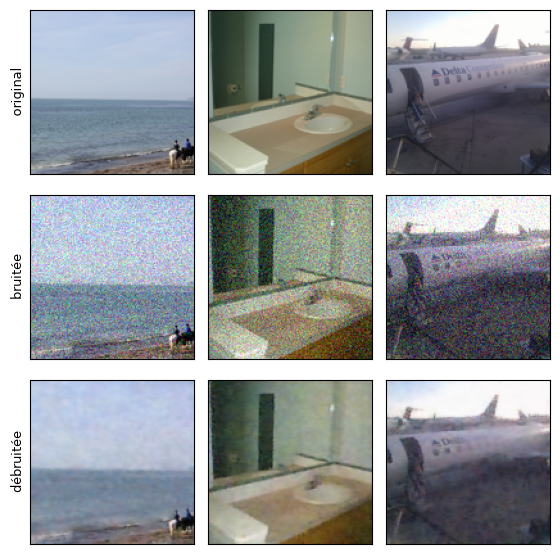

Les 3 plus faibles gains de PSNR


,gain PSNR (dB),gain SSIM,détails
0,4.359,0.186,0.091
1,5.465,0.146,0.114
2,6.001,0.232,0.092


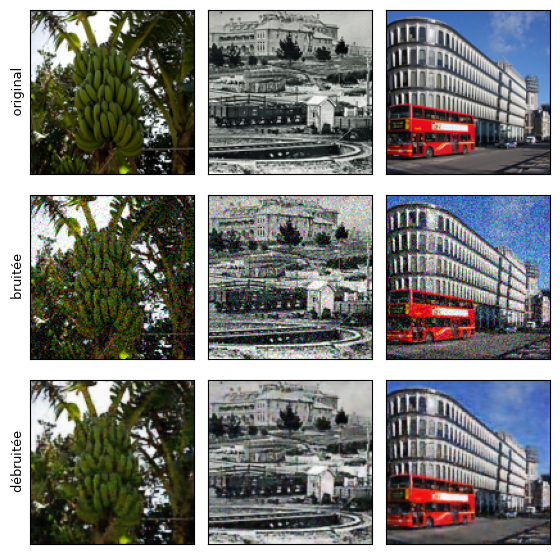

In [ ]:
x = TEST_BRUITE[("gaussien", "moyen")]
prediction = modele_final.predict(x, batch_size=16, verbose=0)

# Gain par photo
gain_psnr = tf.image.psnr(prediction, X_test, 1.0).numpy() - tf.image.psnr(x, X_test, 1.0).numpy()
gain_ssim = tf.image.ssim(prediction, X_test, 1.0).numpy() - tf.image.ssim(x, X_test, 1.0).numpy()

# Quantité de détails : intensité moyenne des contours
gy, gx = np.gradient(X_test.mean(axis=-1), axis=(1, 2))
details = np.sqrt(gx ** 2 + gy ** 2).mean(axis=(1, 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, gain, nom in [(axes[0], gain_psnr, "gain de PSNR (dB)"), (axes[1], gain_ssim, "gain de SSIM")]:
    ax.scatter(details, gain)
    ax.set_xlabel("Quantité de détails de la photo")
    ax.set_ylabel(nom)
    ax.set_title(f"Corrélation : {np.corrcoef(details, gain)[0, 1]:.2f}")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

ordre = np.argsort(gain_psnr)
for titre, idx in [("Les 3 plus forts gains de PSNR", ordre[-3:][::-1]), ("Les 3 plus faibles gains de PSNR", ordre[:3])]:
    print(titre)
    display(pd.DataFrame({"gain PSNR (dB)": gain_psnr[idx], "gain SSIM": gain_ssim[idx],
                          "détails": details[idx]}).round(3))
    afficher([X_test[idx], x[idx], prediction[idx]], ["original", "bruitée", "débruitée"], n=3)

### Analyse : efficacité selon la photo

**Plus une photo est détaillée, moins le modèle l'améliore** (corrélation de −0,87 pour le PSNR et de −0,94 pour le SSIM).

| | Photos simples (mer, salle de bain, avion) | Photos détaillées (feuillage, gare, façade) |
|---|---|---|
| Gain de PSNR | +11,5 à +11,9 dB | +4,4 à +6,0 dB |
| Gain de SSIM | +0,59 à +0,66 | +0,15 à +0,23 |

**Pourquoi ?** Sur une grande surface unie (ciel, mur), le bruit se voit beaucoup et il suffit de lisser pour le retirer : le gain est énorme. Sur une photo pleine de détails, le modèle a du mal à séparer les détails du bruit : il en lisse une partie, et le gain est plus faible.

**Ce que montrent les images :** les photos au plus fort gain ne sont pas parfaites pour autant. Le ciel et les murs deviennent un peu tachés, et les petits détails de l'avion sont effacés. À l'inverse, les photos détaillées gardent leur structure, mais leurs textures fines (feuilles, fenêtres) sont adoucies.

Le gain mesure donc **la facilité du débruitage**, pas la beauté du résultat. C'est pourquoi nous regardons toujours les images en plus des chiffres.

### 12.3 Effet du modèle sur une photo sans bruit ajouté

Ici, **aucun bruit n'est ajouté** : la première ligne montre les photos telles quelles, la seconde ces mêmes photos après passage dans le modèle.

**Pourquoi ce test ?** Dans le pipeline, toutes les photos passeront par le débruitage, y compris celles qui sont déjà propres. Nous vérifions donc que le modèle **n'abîme pas** une photo qui n'a rien à corriger.

Photo sans bruit / photo après le modèle : {'psnr': 34.409, 'ssim': 0.968}


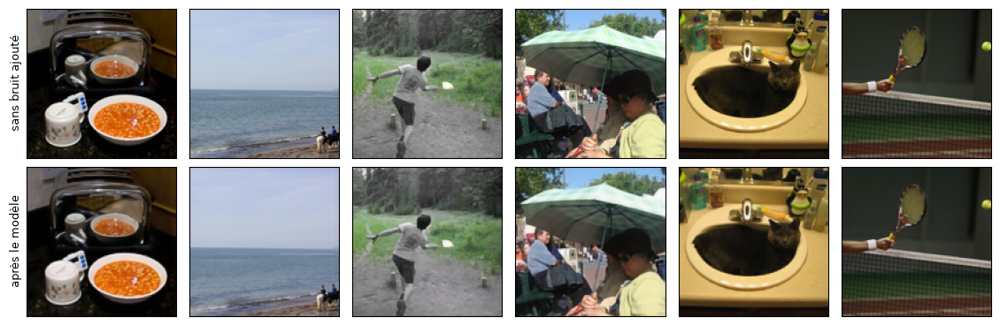

In [ ]:
sortie = modele_final.predict(X_test, batch_size=16, verbose=0)
print("Photo sans bruit / photo après le modèle :", {k: round(v, 3) for k, v in mesurer(sortie, X_test).items()})
afficher([X_test, sortie], ["sans bruit ajouté", "après le modèle"], n=6)

### Analyse : photo sans bruit

Entre la photo d'origine et la photo passée dans le modèle : **34,4 dB et un SSIM de 0,97**. La photo ressort presque identique ; le modèle la lisse très légèrement, sans la dégrader.

Le modèle peut donc être appliqué à toutes les photos du pipeline, bruitées ou non.

## 13. Fonction de débruitage et sauvegarde du modèle

Le modèle final doit pouvoir être réutilisé sans refaire l'entraînement.

Nous sauvegardons :

- le modèle final (architecture et poids) ;
- une fonction `debruiter`, qui nettoie une photo de n'importe quelle taille.

Elle sera utilisée dans le pipeline complet du livrable 3.

In [ ]:
modele_final.save("debruiteur_final.keras")


def debruiter(image, modele=modele_final):
    x = np.asarray(image, dtype="float32") / 255.0
    h, w = x.shape[:2]

    # Le modèle divise la taille par 4 : on complète l'image jusqu'à un multiple de 4
    x = np.pad(x, ((0, -h % 4), (0, -w % 4), (0, 0)), mode="reflect")
    y = modele.predict(x[np.newaxis], verbose=0)[0, :h, :w]
    return (np.clip(y, 0, 1) * 255).astype("uint8")


print("Modèle sauvegardé : debruiteur_final.keras")

Modèle sauvegardé : debruiteur_final.keras


## Conclusion

Notre auto-encodeur convolutif retire le bruit des photos **nettement mieux que les filtres classiques**. Sur le test final, au bruit d'intensité moyenne, il obtient **28,7 dB** sur le bruit gaussien, **32,4 dB** sur le sel et poivre et **28,2 dB** sur le speckle, soit **+3,4 à +3,9 dB** par rapport au meilleur filtre pour chaque bruit. Il est le meilleur dans les **9 cas testés** (3 bruits × 3 intensités), et le SSIM confirme une meilleure conservation des contours (**0,85** contre **0,72** sur le bruit gaussien).

Ce résultat vient d'abord de **l'architecture**. Le modèle de base fait moins bien qu'un simple filtre (**24,7 dB** contre **25,0 dB**), alors que l'ajout de connexions directes (A2, principe du U-Net) apporte **+3,9 dB**. Les réglages de la fonction de perte (MSE) et du taux d'apprentissage (0,003) n'apportent que de faibles gains supplémentaires.

Le choix d'un **modèle mixte**, entraîné sur les trois bruits, est essentiel pour TouNum : un modèle spécialisé échoue face à un bruit inconnu (**20,9 dB** pour le modèle gaussien sur le sel et poivre), alors que le modèle mixte reste efficace sur tous les bruits. Il n'abîme pas non plus les photos déjà propres (**34,4 dB**, SSIM **0,97**).

**Limites :**

- le bruit est simulé : les vraies photos peuvent avoir d'autres défauts, comme le flou, que notre modèle n'a pas appris ;
- le modèle lisse une partie des détails fins, surtout sur les photos très texturées ;
- tous les entraînements se sont arrêtés à la limite de 25 époques : les modèles pouvaient encore progresser ;
- chaque modèle n'a été entraîné qu'une fois : les écarts de moins de 0,5 dB restent à confirmer.

**Pistes d'amélioration :** entraîner plus longtemps et sur toutes les photos, ajouter le flou aux défauts appris, et répéter les meilleurs réglages plusieurs fois.